# Incident Triage RAG Project
### IT7075: Applied AI for Cybersecurity

This notebook completes the five course-pipeline exercises and then builds an offline RAG system over five original incident-triage documents. The project uses local `all-MiniLM-L6-v2` embeddings and an in-memory Chroma vector database. Retrieval scoring does not require an API key or GPU.

Run from the `rag_project/` folder. The final cells save `results.csv` and `figure.png` beside this notebook.

## Part 1 - Practice: chunk the course documents

An embedding is a numeric representation that places semantically similar text near other similar text. Documents are chunked because one vector for a long, multi-topic file blurs its topics. Overlap helps preserve sentences at chunk boundaries. The expected course result is 11 chunks per document, 22 total.

In [1]:
import json, os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

from sentence_transformers import SentenceTransformer
import chromadb

PROJECT = Path.cwd()
if PROJECT.name != "rag_project":
    candidate = PROJECT / "rag_project"
    if candidate.is_dir():
        PROJECT = candidate
    else:
        raise RuntimeError("Open this notebook from the repository root or rag_project folder.")

COURSE_CODE = PROJECT.parent / "04_RAG" / "code"
COURSE_ASSIGNMENT = PROJECT.parent / "04_RAG" / "assignments" / "project"
COURSE_KB = [COURSE_CODE / "ssrf.txt", COURSE_CODE / "cybersecurity_kb.md"]
BASELINE_FILE = COURSE_ASSIGNMENT / "baseline_goldset.json"

embedder = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")
def embed(texts):
    return embedder.encode(texts, normalize_embeddings=True, show_progress_bar=False).tolist()

def split_into_chunks(text, chunk_size=600, overlap=100):
    assert 0 <= overlap < chunk_size
    pieces, start = [], 0
    while start < len(text):
        piece = text[start:start + chunk_size].strip()
        if piece:
            pieces.append(piece)
        start += chunk_size - overlap
    return pieces

def load_and_chunk(files, chunk_size=600, overlap=100):
    chunks, sources = [], []
    for path in files:
        pieces = split_into_chunks(path.read_text(encoding="utf-8"), chunk_size, overlap)
        chunks.extend(pieces)
        sources.extend([path.name] * len(pieces))
        print(f"{path.name:24s} -> {len(pieces):2d} chunks")
    return chunks, sources

course_chunks, course_sources = load_and_chunk(COURSE_KB)
print("TOTAL:", len(course_chunks), "chunks")
assert len(course_chunks) == 22

/home/colinvitols/GitHub/IT7075-Applied-AI-for-Cybersecurity-1/.venv-llmhosting/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8857.63it/s]

ssrf.txt                 -> 11 chunks
cybersecurity_kb.md      -> 11 chunks
TOTAL: 22 chunks


## Part 2 - Practice: embed and store in ChromaDB

Chroma stores each chunk, its embedding, and source metadata. Cosine distance is used, where smaller values mean greater semantic similarity.

In [2]:
client = chromadb.EphemeralClient()
collection_counter = 0

def build_collection(chunks, sources, prefix="kb"):
    global collection_counter
    collection_counter += 1
    collection = client.create_collection(
        f"{prefix}_{collection_counter}", metadata={"hnsw:space": "cosine"}
    )
    collection.add(
        ids=[f"c{i}" for i in range(len(chunks))],
        documents=chunks,
        embeddings=embed(chunks),
        metadatas=[{"source": source} for source in sources],
    )
    return collection

course_collection = build_collection(course_chunks, course_sources, "course")
print("Stored", course_collection.count(), "chunks")
assert course_collection.count() == 22

Stored 22 chunks


## Part 3 - Practice: retrieve close chunks and reject weak matches

The question is embedded with the same model used for document chunks. Chroma returns nearby vectors; the distance threshold removes weak matches so an unrelated question can produce no context.

In [3]:
def retrieve(collection, question, k=4, max_distance=0.75):
    n_results = min(k, collection.count())
    results = collection.query(query_embeddings=embed([question]), n_results=n_results)
    hits = []
    for doc, dist, meta in zip(
        results["documents"][0], results["distances"][0], results["metadatas"][0]
    ):
        if dist <= max_distance:
            hits.append({"text": doc, "distance": float(dist), "source": meta["source"]})
    return hits

for question in [
    "Is SSRF limited to HTTP, or can other protocols be involved?",
    "What is the capital of France?",
]:
    hits = retrieve(course_collection, question)
    print("Q:", question)
    print("hits:", len(hits), [(h["source"], round(h["distance"], 3)) for h in hits])

Q: Is SSRF limited to HTTP, or can other protocols be involved?
hits: 4 [('ssrf.txt', 0.356), ('ssrf.txt', 0.399), ('ssrf.txt', 0.405), ('ssrf.txt', 0.431)]
Q: What is the capital of France?
hits: 0 []


## Part 4 - Practice: augment the prompt and generate a grounded response

RAG has three query-time steps: retrieve relevant chunks, augment the prompt with those chunks, and generate an answer constrained by that context. The offline generator below displays the grounded context rather than inventing an answer when no model API is available.

In [4]:
SYSTEM = (
    "You are a cybersecurity assistant. Answer using ONLY the supplied context. "
    "Cite source filenames. If the context is empty, say you do not know.\n\n"
    "# Context\n{context}"
)

def build_context(hits):
    if not hits:
        return ""
    blocks = []
    for i, hit in enumerate(hits, start=1):
        blocks.append(f"[{i}] (source: {hit['source']})\n{hit['text']}")
    return "\n\n".join(blocks)

def grounded_answer(hits):
    if not hits:
        return "[REFUSAL] I don't know; the knowledge base does not contain relevant evidence."
    lead = hits[0]
    excerpt = " ".join(lead["text"].split())[:360]
    return f"[RAG] Retrieved evidence from [{lead['source']}]: {excerpt}"

def ask(collection, question, k=4, max_distance=0.75, show=True):
    hits = retrieve(collection, question, k, max_distance)
    context = build_context(hits)
    prompt = SYSTEM.format(context=context or "(nothing found)")
    answer = grounded_answer(hits)
    if show:
        print("Q:", question)
        print("Retrieved:", len(hits), "chunk(s)")
        print("Answer:", answer, "\n")
    return {"hits": hits, "context": context, "prompt": prompt, "answer": answer}

ask(course_collection, "What are the two basic cases in which SSRF can happen?")
ask(course_collection, "What CVSS score did Log4Shell receive?")

Q: What are the two basic cases in which SSRF can happen?
Retrieved: 4 chunk(s)
Answer: [RAG] Retrieved evidence from [ssrf.txt]: ed to perform an SSRF attack. Take a look at the XXE cheat sheet to learn how to prevent exposure to XXE. Cases Depending on the application’s functionality and requirements, there are two basic cases in which SSRF can happen: Application can send requests only to identified and trusted applications: This occurs when an allowlist approach is available. Appli 



Q: What CVSS score did Log4Shell receive?
Retrieved: 0 chunk(s)
Answer: [REFUSAL] I don't know; the knowledge base does not contain relevant evidence. 



{'hits': [],
 'context': '',
 'prompt': 'You are a cybersecurity assistant. Answer using ONLY the supplied context. Cite source filenames. If the context is empty, say you do not know.\n\n# Context\n(nothing found)',
 'answer': "[REFUSAL] I don't know; the knowledge base does not contain relevant evidence."}

## Part 5 - Practice: score retrieval

`found` counts answerable questions whose retrieved chunks contain the gold evidence. `refused` counts unanswerable questions that retrieve nothing. Both matter because finding more text while losing refusals can increase guessing.

In [5]:
def found_evidence(hits, evidence):
    return any(
        phrase.lower() in hit["text"].lower()
        for hit in hits for phrase in evidence
    )

def score(collection, goldset, k=4, max_distance=0.75):
    found = refused = 0
    details = []
    for item in goldset:
        hits = retrieve(collection, item["question"], k, max_distance)
        correct = found_evidence(hits, item["evidence"]) if item["answerable"] else len(hits) == 0
        if item["answerable"] and correct:
            found += 1
        if not item["answerable"] and correct:
            refused += 1
        details.append({"qid": item["qid"], "correct": correct, "hits": hits})
    return found, refused, details

baseline_goldset = json.loads(BASELINE_FILE.read_text())["questions"]
found, refused, _ = score(course_collection, baseline_goldset)
print(f"found {found}/6 answerable questions")
print(f"refused {refused}/2 unanswerable questions")
assert (found, refused) == (6, 2)

found 6/6 answerable questions
refused 2/2 unanswerable questions


## Part 6 - My data and gold-set checks

The custom knowledge base contains original procedures for account, endpoint, email, network, and evidence-handling triage. Six questions have exact evidence phrases. Q7 is clearly unrelated. Q8 sounds operationally relevant but asks for a retention period that these files deliberately do not define, making it a stronger refusal test.

In [6]:
KB_DIR = PROJECT / "my_kb"
MY_FILES = sorted(path for path in KB_DIR.glob("*.md") if path.name != "SOURCES.md")
GOLDSET = json.loads((PROJECT / "goldset.json").read_text())["questions"]
documents = {path.name: path.read_text(encoding="utf-8") for path in MY_FILES}

print("Documents:", len(documents))
print("Characters:", sum(len(text) for text in documents.values()))
print("Questions:", len(GOLDSET))
assert 4 <= len(documents) <= 6
assert len(GOLDSET) == 8
assert sum(q["answerable"] for q in GOLDSET) == 6

missing = []
for item in GOLDSET:
    for phrase in item["evidence"]:
        if phrase not in documents[item["source"]]:
            missing.append((item["qid"], phrase))
assert not missing, f"Evidence phrases missing: {missing}"
print("PASS: every answerable evidence phrase appears exactly in its source document.")

Documents: 5
Characters: 10209
Questions: 8
PASS: every answerable evidence phrase appears exactly in its source document.


## Part 7 - Build my vector store and show a transcript

The default configuration uses 500-character chunks with 80-character overlap, retrieves up to three chunks, and rejects cosine distances above 0.50.

In [7]:
def build_my_rag(chunk_size=500, overlap=80):
    chunks, sources = load_and_chunk(MY_FILES, chunk_size, overlap)
    return build_collection(chunks, sources, "incident"), chunks

DEFAULTS = {"chunk_size": 500, "overlap": 80, "k": 3, "max_distance": 0.50}
my_collection, my_chunks = build_my_rag(DEFAULTS["chunk_size"], DEFAULTS["overlap"])
print("Custom vector store contains", my_collection.count(), "chunks.")

for item in [GOLDSET[0], GOLDSET[2], GOLDSET[5], GOLDSET[6], GOLDSET[7]]:
    ask(my_collection, item["question"], DEFAULTS["k"], DEFAULTS["max_distance"])

account_triage.md        ->  5 chunks
email_triage.md          ->  5 chunks
endpoint_triage.md       ->  5 chunks
evidence_and_escalation.md ->  6 chunks
network_triage.md        ->  5 chunks


Custom vector store contains 26 chunks.
Q: How should failed sign-ins followed by a successful sign-in be preserved?
Retrieved: 1 chunk(s)
Answer: [RAG] Retrieved evidence from [account_triage.md]: by success, **preserve the failed and successful sign-in events as one timeline**. Review multifactor authentication events, password-reset activity, mailbox rules, OAuth grants, and changes to recovery information. A success with a previously registered device is different from a success that also creates a new device registration. ## Containment Containmen 

Q: What should an analyst preserve from a suspected phishing email?
Retrieved: 2 chunk(s)
Answer: [RAG] Retrieved evidence from [email_triage.md]: # Suspicious Email Triage ## Preserve the message A screenshot is useful for communication but does not contain all evidence. Preserve the original message or an approved export so headers, attachment hashes, URLs, and routing details remain available. Handle potentially malicious attachment

Q: What is the recommended watering schedule for tomato seedlings?
Retrieved: 0 chunk(s)
Answer: [REFUSAL] I don't know; the knowledge base does not contain relevant evidence. 



Q: What exact SIEM retention period does this incident-triage program require?
Retrieved: 0 chunk(s)
Answer: [REFUSAL] I don't know; the knowledge base does not contain relevant evidence. 



## Part 8 - Experiments

Each row changes one setting from the default. The evaluation checks evidence retrieval for six answerable questions and empty retrieval for two unanswerable questions. `balanced_score` is the sum of the answer and refusal rates, so both objectives have equal weight despite different question counts.

In [8]:
experiments = [
    {"label": "default", **DEFAULTS},
    {"label": "chunk_350", **DEFAULTS, "chunk_size": 350, "overlap": 60},
    {"label": "chunk_700", **DEFAULTS, "chunk_size": 700, "overlap": 100},
    {"label": "k_1", **DEFAULTS, "k": 1},
    {"label": "k_5", **DEFAULTS, "k": 5},
    {"label": "threshold_0.35", **DEFAULTS, "max_distance": 0.35},
    {"label": "threshold_0.65", **DEFAULTS, "max_distance": 0.65},
    {"label": "threshold_0.80", **DEFAULTS, "max_distance": 0.80},
]

rows = []
for config in experiments:
    test_collection, test_chunks = build_my_rag(config["chunk_size"], config["overlap"])
    found, refused, details = score(
        test_collection, GOLDSET, config["k"], config["max_distance"]
    )
    rows.append({
        **config,
        "chunks": len(test_chunks),
        "found": found,
        "answerable_total": 6,
        "refused": refused,
        "unanswerable_total": 2,
        "answer_rate": found / 6,
        "refusal_rate": refused / 2,
        "balanced_score": found / 6 + refused / 2,
        "incorrect_qids": ",".join(d["qid"] for d in details if not d["correct"]),
    })

results = pd.DataFrame(rows)
results.to_csv(PROJECT / "results.csv", index=False)
results

account_triage.md        ->  5 chunks
email_triage.md          ->  5 chunks
endpoint_triage.md       ->  5 chunks
evidence_and_escalation.md ->  6 chunks
network_triage.md        ->  5 chunks


account_triage.md        ->  7 chunks
email_triage.md          ->  7 chunks
endpoint_triage.md       ->  7 chunks
evidence_and_escalation.md ->  8 chunks
network_triage.md        ->  8 chunks


account_triage.md        ->  4 chunks
email_triage.md          ->  4 chunks
endpoint_triage.md       ->  4 chunks
evidence_and_escalation.md ->  4 chunks
network_triage.md        ->  4 chunks


account_triage.md        ->  5 chunks
email_triage.md          ->  5 chunks
endpoint_triage.md       ->  5 chunks
evidence_and_escalation.md ->  6 chunks
network_triage.md        ->  5 chunks


account_triage.md        ->  5 chunks
email_triage.md          ->  5 chunks
endpoint_triage.md       ->  5 chunks
evidence_and_escalation.md ->  6 chunks
network_triage.md        ->  5 chunks


account_triage.md        ->  5 chunks
email_triage.md          ->  5 chunks
endpoint_triage.md       ->  5 chunks
evidence_and_escalation.md ->  6 chunks
network_triage.md        ->  5 chunks


account_triage.md        ->  5 chunks
email_triage.md          ->  5 chunks
endpoint_triage.md       ->  5 chunks
evidence_and_escalation.md ->  6 chunks
network_triage.md        ->  5 chunks


account_triage.md        ->  5 chunks
email_triage.md          ->  5 chunks
endpoint_triage.md       ->  5 chunks
evidence_and_escalation.md ->  6 chunks
network_triage.md        ->  5 chunks


,label,chunk_size,overlap,k,max_distance,chunks,found,answerable_total,refused,unanswerable_total,answer_rate,refusal_rate,balanced_score,incorrect_qids
0,default,500,80,3,0.50,26,6,6,2,2,1.000000,1.0,2.000000,
1,chunk_350,350,60,3,0.50,37,4,6,2,2,0.666667,1.0,1.666667,"Q1,Q6"
2,chunk_700,700,100,3,0.50,20,4,6,2,2,0.666667,1.0,1.666667,"Q1,Q4"
3,k_1,500,80,1,0.50,26,5,6,2,2,0.833333,1.0,1.833333,Q3
4,k_5,500,80,5,0.50,26,6,6,2,2,1.000000,1.0,2.000000,
5,threshold_0.35,500,80,3,0.35,26,2,6,2,2,0.333333,1.0,1.333333,"Q1,Q3,Q4,Q6"
6,threshold_0.65,500,80,3,0.65,26,6,6,1,2,1.000000,0.5,1.500000,Q8
7,threshold_0.80,500,80,3,0.80,26,6,6,1,2,1.000000,0.5,1.500000,Q8


## Part 9 - Chart and interpretation

The chart keeps answer retrieval and refusal retention visible as separate measures. A setting is not better merely because it retrieves more answer evidence if it also retrieves irrelevant chunks for questions the knowledge base cannot answer.

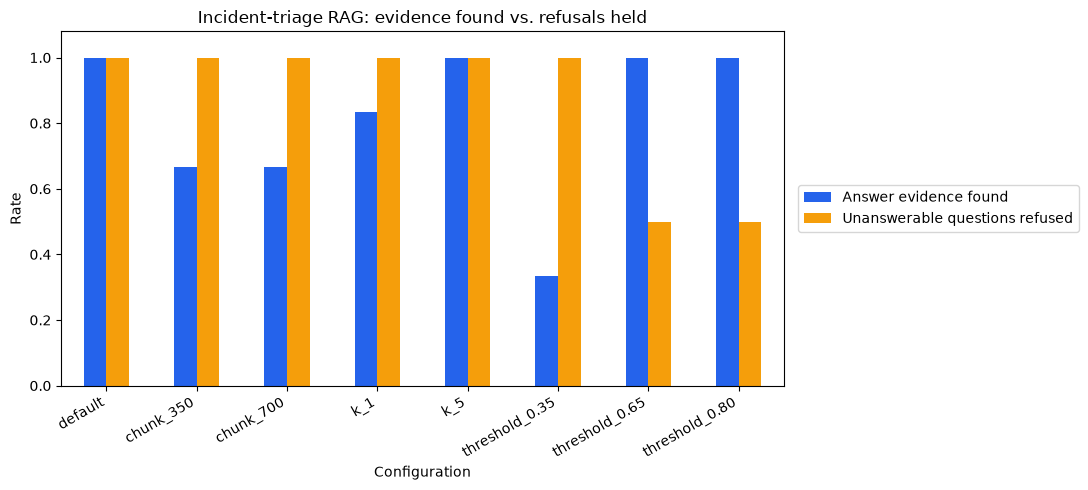

Best measured configuration: default
Found: 6 /6; refused: 2 /2
Saved: /home/colinvitols/GitHub/IT7075-Applied-AI-for-Cybersecurity-1/rag_project/results.csv
Saved: /home/colinvitols/GitHub/IT7075-Applied-AI-for-Cybersecurity-1/rag_project/figure.png


In [9]:
ax = results.set_index("label")[["answer_rate", "refusal_rate"]].plot(
    kind="bar", figsize=(11, 5), color=["#2563eb", "#f59e0b"]
)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Rate")
ax.set_xlabel("Configuration")
ax.set_title("Incident-triage RAG: evidence found vs. refusals held")
ax.legend(
    ["Answer evidence found", "Unanswerable questions refused"],
    loc="center left", bbox_to_anchor=(1.01, 0.5)
)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(PROJECT / "figure.png", dpi=180, bbox_inches="tight")
plt.show()

best = results.sort_values(["balanced_score", "refusal_rate", "answer_rate"], ascending=False).iloc[0]
print("Best measured configuration:", best["label"])
print("Found:", int(best["found"]), "/6; refused:", int(best["refused"]), "/2")
print("Saved:", PROJECT / "results.csv")
print("Saved:", PROJECT / "figure.png")

## Part 10 - Error analysis and limits

The strict `threshold_0.35` experiment provides a concrete error for the report. Re-running a missed question with a wider threshold shows whether the strict cutoff rejected useful evidence. A miss can also occur because the embedding ranked a related chunk above the evidence chunk or because a chunk boundary separated the key phrase from its topic.

This gold set is deliberately small. Each answerable question contributes one-sixth of the answer score, and each unanswerable question contributes one-half of the refusal score. These measurements describe this five-document knowledge base and these eight questions; they do not establish general incident-response accuracy, factual generation quality, or safe production performance.

In [10]:
error_row = results.loc[results["label"] == "threshold_0.35"].iloc[0]
print("Questions missed at threshold 0.35:", error_row["incorrect_qids"] or "none")
for item in GOLDSET:
    if item["qid"] in error_row["incorrect_qids"].split(","):
        wide_hits = retrieve(my_collection, item["question"], k=5, max_distance=1.0)
        print("\nQuestion:", item["question"])
        for hit in wide_hits[:3]:
            print(round(hit["distance"], 3), hit["source"], "-", " ".join(hit["text"].split())[:220])
        break

Questions missed at threshold 0.35: Q1,Q3,Q4,Q6

Question: How should failed sign-ins followed by a successful sign-in be preserved?
0.41 account_triage.md - by success, **preserve the failed and successful sign-in events as one timeline**. Review multifactor authentication events, password-reset activity, mailbox rules, OAuth grants, and changes to recovery information. A su
0.521 account_triage.md - # Account Compromise Triage ## Purpose Account alerts become urgent when several weak signals form one credible sequence. A failed login alone may be a typing mistake. A successful login after repeated failures, a new de
0.548 account_triage.md - hould be revoked, the password reset through the approved identity process, and risky tokens invalidated. If compromise is uncertain, a step-up authentication challenge may preserve access while the analyst gathers evide
